# 04 — The line fluxes of the mock

Notebook 01 counts the galaxies whose lines exceed the flux thresholds: dN/dz (cell 3), the comoving number
density (cell 4) and the single-line fraction (cell 7). This notebook looks at the fluxes themselves, for
**every galaxy of the mock, with no flux cut**: the quantiles of the flux of each line as a function of
redshift, and the fraction of galaxies above the thresholds. The counts of notebook 01 follow from them.

The fluxes are read from the input mock directly by `romanmock flux-distribution` (part of
`scripts/production.sh`), which histograms log₁₀ F in bins of 0.02 dex per redshift bin of 0.01, for the nine
lines, over the 324 M galaxies of the lightcone. Dust attenuation is included; the luminosity distance uses
the cosmological redshift. The thresholds shown are the ones in use: 4×10⁻¹⁷, 8×10⁻¹⁷, 10⁻¹⁶ and
1.5×10⁻¹⁶ erg s⁻¹ cm⁻².

In [ ]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # diffsky imports JAX; keep it off the GPU

import numpy as np
import matplotlib.pyplot as plt
from romanmock import plotting

plotting.use_style()

MOCK = "sdss_feniks_hizels_260710_09_07_2026"                          # version of the diffsky mock
ROOT = f"/global/cfs/cdirs/m4943/Simulations/RomanMocks/{MOCK}"        # products of romanmock for this mock

In [ ]:
from romanmock.fluxdist import FluxDistribution
from romanmock.lines import get_line_set

dist = FluxDistribution.load(f"{ROOT}/census/flux_distribution.npz")
line_set = get_line_set("roman_transitions")
z = dist.z

THRESHOLDS = {4e-17: ":", 8e-17: "-.", 1e-16: "--", 1.5e-16: "-"}       # erg/s/cm^2: line style of the marker
WAVE_RANGE = (10000.0, 19300.0)                                         # Angstrom, the grism bandpass
LABEL = {"Ha": "Hα", "Hb": "Hβ", "OIII_5007": "[O III] λ5007", "OIII_4959": "[O III] λ4959", "OII_3727": "[O II] λ3727",
         "SIII_9532": "[S III] λ9532", "SIII_9069": "[S III] λ9069", "OIII_4363": "[O III] λ4363", "SIII_6312": "[S III] λ6312"}
sci = lambda x: (lambda m, e: rf"${m}\times10^{{{int(e)}}}$")(*f"{x:.1f}e{int(np.floor(np.log10(x)))}".replace("e", " ").split()) \
    if False else (rf"${float(f'{x:.1e}'.split('e')[0]):g}\times10^{{{int(f'{x:.1e}'.split('e')[1])}}}$")

def band(line):
    """Redshift range in which the line is inside the grism bandpass."""
    rest = line_set.rest_waves[line_set.bit(line)]
    return WAVE_RANGE[0] / rest - 1, WAVE_RANGE[1] / rest - 1

print(f"{len(dist.steps)} slices, {dist.n_gal.sum():,} galaxies, {dist.z_edges[0]:.1f} < z < {dist.z_edges[-1]:.1f}, "
      f"bins of {dist.z_edges[1] - dist.z_edges[0]:.2f} in z and {dist.logf_edges[1] - dist.logf_edges[0]:.2f} dex in flux")

## Flux quantiles

For each line, the median flux (solid) and the bands from the median to the 90 % quantile (dark) and from the 90 % to the
99.9 % quantile (light) of all galaxies at that redshift: the upper half of the distribution, the one the thresholds act on.
The grey area is where the line is inside the grism bandpass; the horizontal lines are the thresholds.
Galaxies without the line (zero flux) are included in the quantiles, at the faint end.

The curves show a sawtooth with a period of 0.05–0.08 in redshift: the lightcone is built from snapshots, and within one slice the galaxies carry the line luminosities of one snapshot while the flux falls with the luminosity distance across the slice, then jumps at the next slice. It is a feature of the mock, resolved by the redshift bins of 0.01.

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10.5), sharex=True, sharey=True, constrained_layout=True)
for ax, line in zip(axes.ravel(), dist.line_names):
    lo, hi = band(line)
    ax.axvspan(max(lo, z[0] - 0.05), min(hi, z[-1] + 0.05), color=plotting.GRID, alpha=0.6, zorder=0)
    col = plotting.feature_color(line)
    ax.fill_between(z, dist.quantile(line, 0.5), dist.quantile(line, 0.9),  color=col, alpha=0.5, lw=0, label="0.5 – 0.9")
    ax.fill_between(z, dist.quantile(line, 0.9), dist.quantile(line, 0.999), color=col, alpha=0.18, lw=0, label="0.9 – 0.999")
    ax.plot(z, dist.quantile(line, 0.5), color=col, lw=1.8, label="median")
    for value, ls in THRESHOLDS.items():
        ax.axhline(value, color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls)
    ax.set_yscale("log")
    ax.set_ylim(1e-19, 1e-12)
    ax.set_xlim(z[0], z[-1])
    ax.set_title(f"{LABEL[line]}  ({line_set.rest_waves[line_set.bit(line)]:.0f} Å)", loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("line flux [erg s$^{-1}$ cm$^{-2}$]")
for ax in axes[-1]:
    ax.set_xlabel("redshift")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
handles = [Line2D([], [], color=plotting.TEXT_PRIMARY, lw=1.8, label="median"),
           Patch(color=plotting.TEXT_PRIMARY, alpha=0.18, label="(50 % – 90 %) & (90 % – 99.9 %) "),
           Patch(color=plotting.GRID, label="line inside the grism bandpass")]
handles += [Line2D([], [], color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls, label=f"threshold {sci(v)}") for v, ls in THRESHOLDS.items()]
fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False)
plt.show()

### All lines in one panel

The same quantiles for the seven lines that matter for the catalog ([O III] λ4363 and [S III] λ6312 are too
faint to be detected and are left out), each drawn **only over the redshift range in which the line is inside
the grism bandpass** (10 000–19 300 Å). The solid line is the median, the shaded band runs from the median
to the maximum. Where the bands of two lines overlap, both lines are available to the same galaxies.

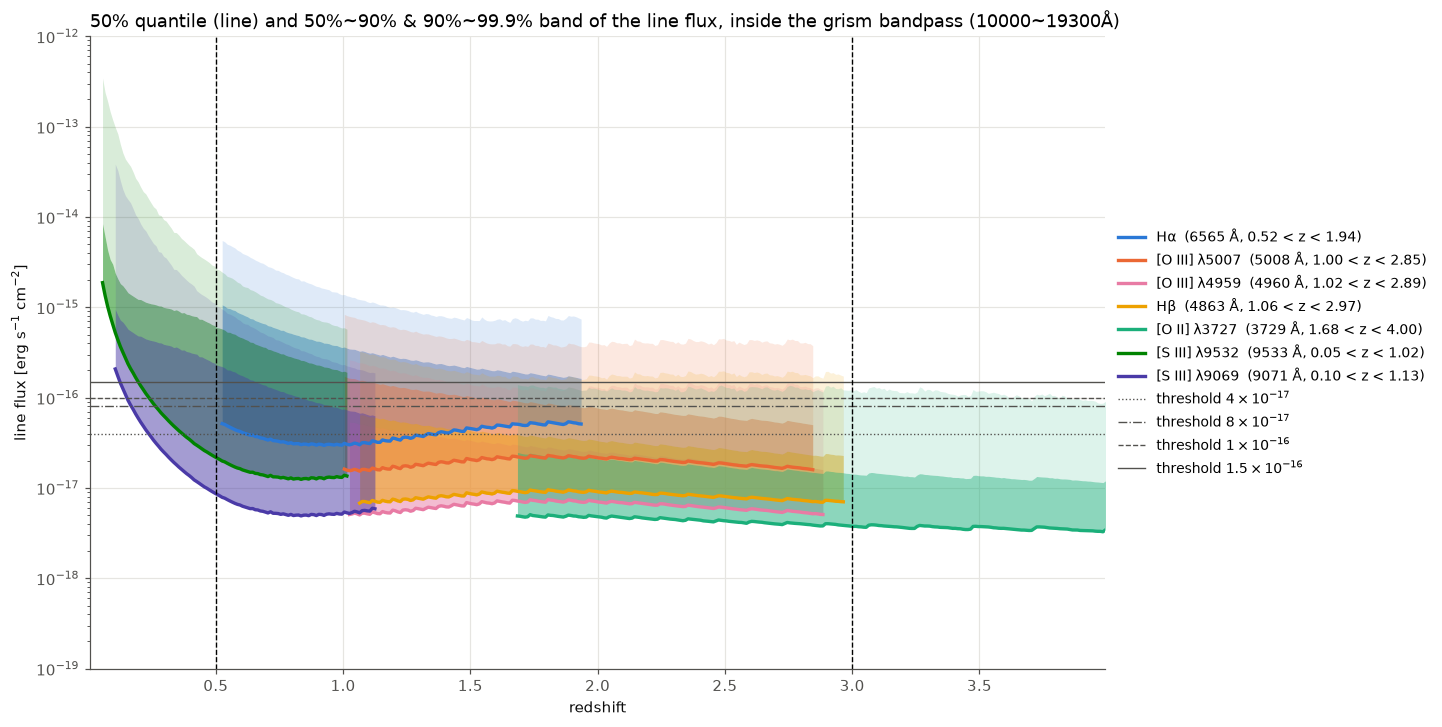

In [6]:
ONE_PANEL = ["Ha", "OIII_5007", "OIII_4959", "Hb", "OII_3727", "SIII_9532", "SIII_9069"]

fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
for line in ONE_PANEL:
    lo, hi = band(line)
    inside = (z > lo) & (z < hi)                                   # redshift bins with the line in the bandpass
    col = plotting.feature_color(line)
    rest = line_set.rest_waves[line_set.bit(line)]
    ax.fill_between(z[inside], dist.quantile(line, 0.5)[inside], dist.quantile(line, 0.9)[inside], color=col, alpha=0.5, lw=0)
    ax.fill_between(z[inside], dist.quantile(line, 0.9)[inside], dist.quantile(line, 0.999)[inside], color=col, alpha=0.15, lw=0)
    ax.plot(z[inside], dist.quantile(line, 0.5)[inside], color=col, lw=2.2,
            label=f"{LABEL[line]}  ({rest:.0f} Å, {max(lo, 0):.2f} < z < {min(hi, z[-1]):.2f})")
for value, ls in THRESHOLDS.items():
    ax.axhline(value, color=plotting.TEXT_SECONDARY, lw=0.9, ls=ls, label=f"threshold {sci(value)}")
ax.axvline(0.5, color="black", lw=0.9, ls="dashed")
ax.axvline(3.0, color="black", lw=0.9, ls="dashed")
ax.set_yscale("log")
ax.set_ylim(1e-19, 1e-12)
ax.set_xlim(z[0], z[-1])
ax.set_xlabel("redshift")
ax.set_ylabel("line flux [erg s$^{-1}$ cm$^{-2}$]")
ax.set_title("50% quantile (line) and 50%~90% & 90%~99.9% band of the line flux, inside the grism bandpass (10000~19300Å)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()


## Fraction of galaxies above the thresholds

The fraction of all galaxies at a redshift whose line exceeds each threshold. The number of emitters above a
threshold (the "all" curves of notebook 01, cells 3 and 4) is this fraction times the number of galaxies in the
redshift bin, inside the bandpass.

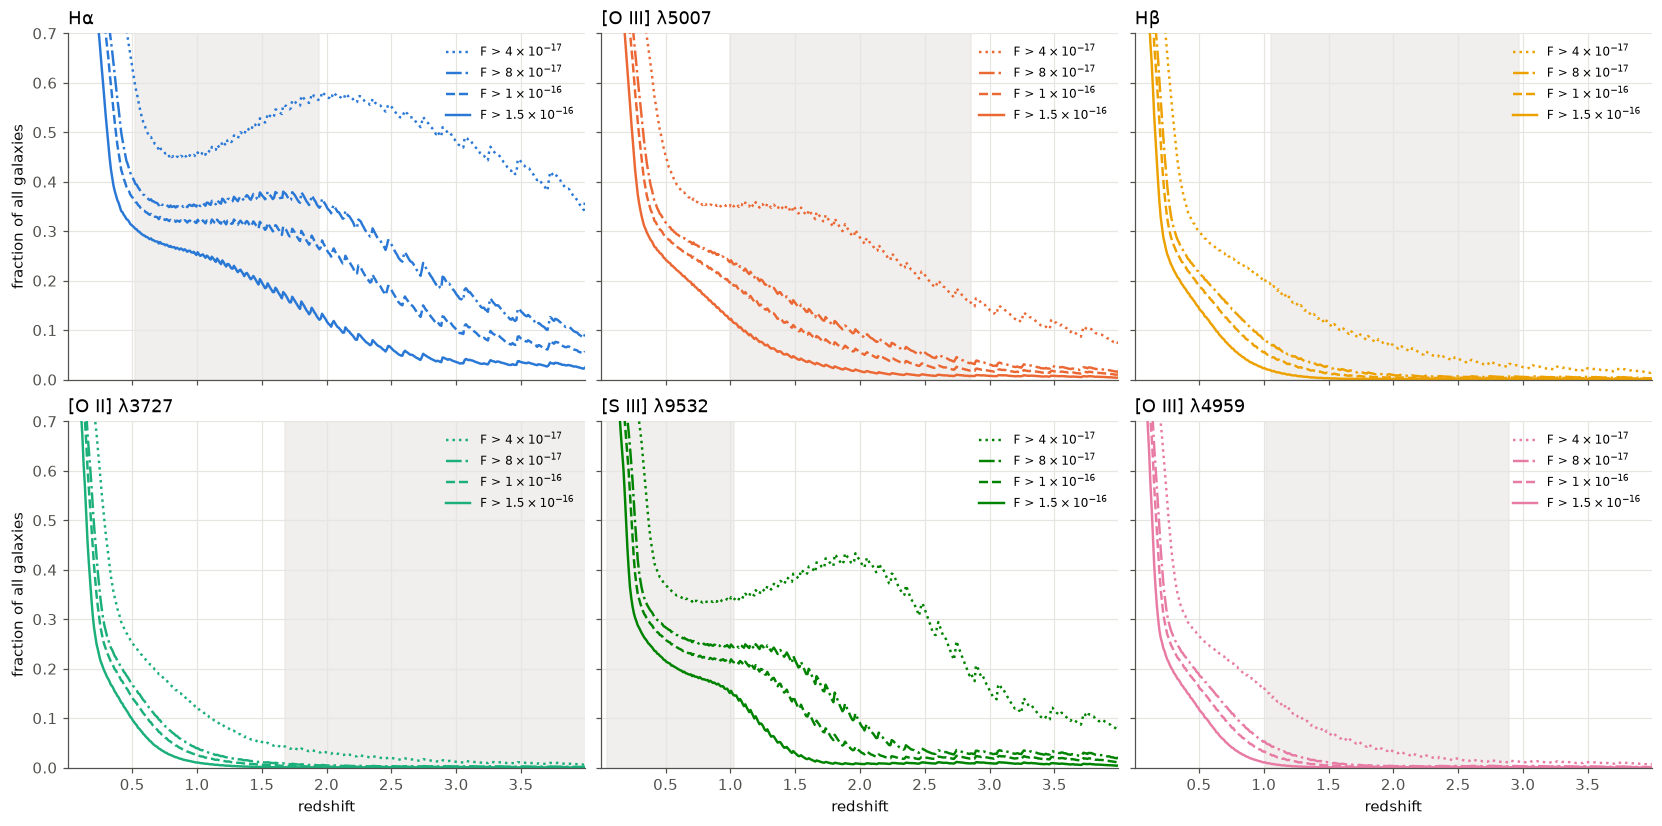

galaxies per redshift bin of 0.01 (millions): [0.71, 1.34, 1.19, 1.19, 0.85, 0.59, 0.34] at z = [0.505, 1.005, 1.505, 2.005, 2.505, 3.005, 3.505]
Hα             median flux [-16.51, -16.29, -16.42] (log10, at z [1.0, 2.0, 3.0]); fraction above 1e-16: [0.323, 0.26, 0.1]
[O III] λ5007  median flux [-16.79, -16.67, -16.82] (log10, at z [1.0, 2.0, 3.0]); fraction above 1e-16: [0.199, 0.054, 0.018]
Hβ             median flux [-17.14, -17.04, -17.17] (log10, at z [1.0, 2.0, 3.0]); fraction above 1e-16: [0.056, 0.004, 0.003]


In [5]:
SHOW = ["Ha", "OIII_5007", "Hb", "OII_3727", "SIII_9532", "OIII_4959"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True, sharey=True, constrained_layout=True)
for ax, line in zip(axes.ravel(), SHOW):
    lo, hi = band(line)
    ax.axvspan(max(lo, z[0] - 0.05), min(hi, z[-1] + 0.05), color=plotting.GRID, alpha=0.6, zorder=0)
    for value, ls in THRESHOLDS.items():
        ax.plot(z, dist.fraction_above(line, value), color=plotting.feature_color(line), ls=ls, lw=1.6, label=f"F > {sci(value)}")
    ax.set_ylim(0, 0.7)
    ax.set_xlim(z[0], z[-1])
    ax.set_title(LABEL[line], loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of all galaxies")
for ax in axes[-1]:
    ax.set_xlabel("redshift")
plt.show()

at = np.searchsorted(z, [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5])                     # bins at these redshifts
dz = dist.z_edges[1] - dist.z_edges[0]
print(f"galaxies per redshift bin of {dz:.2f} (millions):", np.round(dist.n_gal[at] / 1e6, 2).tolist(), "at z =", np.round(z[at], 3).tolist())
for line in ("Ha", "OIII_5007", "Hb"):
    print(f"{LABEL[line]:<14s} median flux {np.log10(dist.quantile(line, 0.5))[at[1::2]].round(2).tolist()} (log10, at z {np.round(z[at[1::2]], 2).tolist()}); "
          f"fraction above 1e-16: {dist.fraction_above(line, 1e-16)[at[1::2]].round(3).tolist()}")

## What this explains in notebook 01

**The shape of dN/dz and n(z) (cells 3 and 4).** The emitter counts are the product of two factors shown
here: the number of galaxies per redshift bin, which peaks at z ≈ 1 and falls by a factor of 4 to z = 3.5, and
the fraction of them above the threshold. The flux quantiles decline only slowly with redshift (the mock's
galaxies at high redshift are intrinsically brighter), but the thresholds sit close to the median flux, where
the distribution is steep, so the fraction above the threshold drops quickly: for [O III] λ5007 from 19 % at
z = 1 to 6 % at z = 2 and 2 % at z = 3. That is the steep decline of the [O III] curves beyond z = 2, where
Hα has left the bandpass. For Hα the fraction above 10⁻¹⁶ is 27–35 % over the whole bandpass, so its dN/dz
follows the galaxy counts.

**The step from 1.0×10⁻¹⁶ to 1.5×10⁻¹⁶.** Between these two thresholds the Hα distribution contains about a
third of the emitters above 10⁻¹⁶ (notebook 01 found 39 M against 56 M in the bandpass): a 50 % change in
the threshold changes the sample by that much because the thresholds are near the median flux.

**The lines a secondary threshold adds.** Hβ, [O III] λ4959 and [O II] lie 3 to 10 times below Hα and
[O III] λ5007. Above 10⁻¹⁶ only a few per cent of the galaxies have them; above 4×10⁻¹⁷ several times more.
This is why the "all" curves of these lines in notebook 01 rise with a lower secondary threshold while the
Hα curve does not move.

**The faint end of the flux histograms (cells 5 and 6).** The counts per logarithmic flux interval are flat
between 10⁻¹⁷ and 10⁻¹⁶ because the median Hα flux of the mock is 3–5×10⁻¹⁷ at every redshift: the
histogram peaks at the median of a broad distribution. The faint-end rise of an observed luminosity function
is absent, which reflects the galaxy population of the mock (its stellar-mass completeness), not the pipeline.

## The lines of a selected galaxy

The single-line fraction (cell 7) depends on the *joint* distribution: given that a galaxy is selected by one
line, how often does another line exceed the line-detection threshold? The flux histograms above are
marginal, so this part uses the base catalog, which is complete above 10⁻¹⁷ and therefore contains every line
above the thresholds of a galaxy selected at 10⁻¹⁶. Galaxies selected by Hα (0.52 < z < 1.94) and by
[O III] λ5007 where Hα is outside the bandpass (1.94 < z < 2.85).

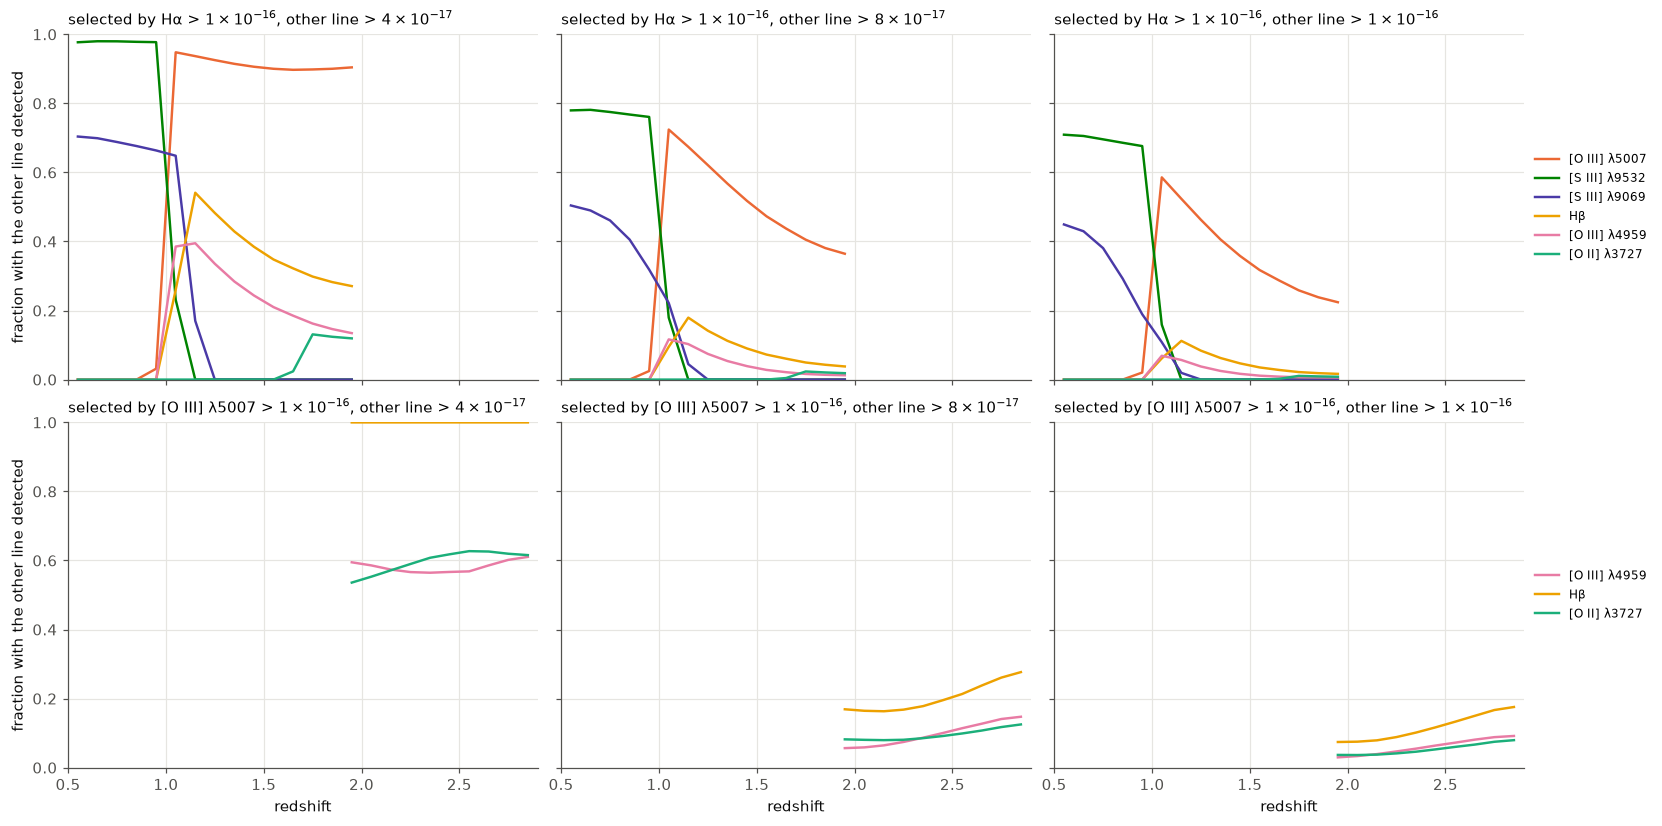

Hα             selected, other line > 4e-17: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.02, 0.06, 0.1, 0.1]


Hα             selected, other line > 8e-17: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.22, 0.33, 0.56, 0.62]


Hα             selected, other line > 1e-16: single-line fraction at z [0.65, 1.15, 1.65, 1.85] = [0.29, 0.48, 0.71, 0.76]


[O III] λ5007  selected, other line > 4e-17: single-line fraction at z [2.05, 2.45, 2.85] = [0.0, 0.0, 0.0]


[O III] λ5007  selected, other line > 8e-17: single-line fraction at z [2.05, 2.45, 2.85] = [0.84, 0.8, 0.72]


[O III] λ5007  selected, other line > 1e-16: single-line fraction at z [2.05, 2.45, 2.85] = [0.92, 0.88, 0.82]


In [6]:
from romanmock import BaseCatalog

base = BaseCatalog(f"{ROOT}/base")
F_SEL = 1.0e-16
lines_all = ["Ha", "OIII_5007", "OIII_4959", "Hb", "OII_3727", "SIII_9532", "SIII_9069"]
sample = base.make_catalog(flux_limit=F_SEL, secondary_flux_limit=None, outcomes=None, z_column="redshift_rsd",
                           z_range=(0.5, 2.9), columns=["redshift_rsd", *[f"{l}_flux" for l in lines_all]], verbose=False)
zs = sample["redshift_rsd"]
flux = {l: sample[f"{l}_flux"] for l in lines_all}
edges = np.arange(0.5, 2.9 + 1e-9, 0.1)
zc = 0.5 * (edges[1:] + edges[:-1])

def in_band(line, redshift):
    lo, hi = band(line)
    return (redshift > lo) & (redshift < hi)

def fraction_with(selected, other, limit):
    """Per redshift bin: fraction of the selected galaxies whose line `other` is inside the bandpass and above `limit`."""
    has = selected & in_band(other, zs) & (flux[other] > limit)
    n_sel, n_has = np.histogram(zs[selected], bins=edges)[0], np.histogram(zs[has], bins=edges)[0]
    with np.errstate(invalid="ignore"):
        return np.where(n_sel > 1000, n_has / n_sel, np.nan)

SELECTIONS = {"Ha": ["OIII_5007", "SIII_9532", "SIII_9069", "Hb", "OIII_4959", "OII_3727"],
              "OIII_5007": ["OIII_4959", "Hb", "OII_3727"]}
F_LINE = [4e-17, 8e-17, 1e-16]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True, sharey=True, constrained_layout=True)
for row, (sel_line, others) in zip(axes, SELECTIONS.items()):
    selected = in_band(sel_line, zs) & (flux[sel_line] > F_SEL)
    if sel_line == "OIII_5007":
        selected &= ~in_band("Ha", zs)
    for ax, f_line in zip(row, F_LINE):
        for other in others:
            ax.plot(zc, fraction_with(selected, other, f_line), color=plotting.feature_color(other), lw=1.6, label=LABEL[other])
        ax.set_ylim(0, 1)
        ax.set_xlim(edges[0], edges[-1])
        ax.set_title(rf"selected by {LABEL[sel_line]} > {sci(F_SEL)}, other line > {sci(f_line)}", loc="left", fontsize=10)
    row[0].set_ylabel("fraction with the other line detected")
    row[-1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
for ax in axes[-1]:
    ax.set_xlabel("redshift")
plt.show()

for sel_line, others in SELECTIONS.items():
    selected = in_band(sel_line, zs) & (flux[sel_line] > F_SEL)
    if sel_line == "OIII_5007":
        selected &= ~in_band("Ha", zs)
    for f_line in F_LINE:
        any_other = np.zeros(zs.size, dtype=bool)
        for other in others:
            any_other |= in_band(other, zs) & (flux[other] > f_line)
        n_sel, n_any = np.histogram(zs[selected], bins=edges)[0], np.histogram(zs[selected & any_other], bins=edges)[0]
        with np.errstate(invalid="ignore"):
            single = np.where(n_sel > 1000, 1 - n_any / n_sel, np.nan)
        picks = [1, 6, 11, 13] if sel_line == "Ha" else [15, 19, 23]
        print(f"{LABEL[sel_line]:<14s} selected, other line > {f_line:.0e}: single-line fraction at z {np.round(zc[picks], 2).tolist()} = "
              f"{np.round(single[picks], 2).tolist()}")
del sample, flux

**The single-line fraction of Hα (cell 7).** An Hα emitter is single-line when none of its other in-band lines
passes the line-detection threshold. Below z ≈ 1.0 the [S III] λ9532 line is inside the bandpass and, in the
mock, it carries 0.35–0.8 of the Hα flux (median 0.47): above 4×10⁻¹⁷ it is present in 98 % of the Hα
emitters, so almost none of them is single-line there. The jump of the Hα single-line fraction at
z ≈ 1.0–1.1 in notebook 01 is [S III] λ9532 leaving the bandpass (z = 1.02), followed by [S III] λ9069
(z = 1.13). Above that the companion is [O III] λ5007, at 0.3–0.7 of Hα (median 0.44): with a threshold of
4×10⁻¹⁷ it is detected in 90 % of the Hα emitters, with 8×10⁻¹⁷ in 70 % falling to 35 % at z = 1.9, and with
10⁻¹⁶ in 60 % falling to 20 %. The fall with redshift comes from the Hα emitters close to the selection
threshold, whose share grows with redshift. Hβ, at 0.19 of Hα, contributes only at the lowest threshold.

**The single-line fraction of [O III] λ5007 beyond z = 1.94.** In the mock the ratios to λ5007 are nearly
fixed: λ4959 at 0.329 (0.323–0.332) and Hβ at 0.45 (0.42–0.47). An [O III] emitter above 10⁻¹⁶ therefore
has Hβ above 4.2×10⁻¹⁷ in every case, and λ4959 above 4×10⁻¹⁷ as soon as λ5007 exceeds 1.2×10⁻¹⁶: with a
line-detection threshold of 4×10⁻¹⁷ no [O III] emitter is single-line. With 8×10⁻¹⁷, Hβ passes only when
λ5007 exceeds 1.8×10⁻¹⁶ (17–28 % of the emitters) and λ4959 when it exceeds 2.4×10⁻¹⁶: the single-line
fraction is 72–84 %. With a threshold equal to the selection threshold it is 82–92 %, the values of
notebook 01. The near-fixed ratios are a property of the line model of the mock, not of its galaxy population.